1. Data Understanding

In [2]:
import pandas as pd

df = pd.read_stata("lfs_2025_mon.dta", convert_categoricals=False)

print(df.shape)
df.head()

(50811, 203)


,axc_id,year,quarter,month,axcaimagcode,psu,ssu,surcode,r1_hour1,r1_minut1,...,k08b,k08c,k08d,k08e,k08f,k08g,k08h,k09,k10,weight_cal_y
0,251000102,25,1,1,11,1,2,1,14,56,...,4.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,40.887321
1,251000102,25,1,1,11,1,2,1,14,56,...,5.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3.0,38.998837
2,251000102,25,1,1,11,1,2,1,14,56,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,251000102,25,1,1,11,1,2,1,14,56,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,251000102,25,1,1,11,1,2,1,14,56,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Мөр бүрийн тайлбар
Код	Юу хийдэг вэ
import pandas as pd	Pandas санг pd гэсэн богино нэрээр дуудна
pd.read_stata(...)	Stata (.dta) файлыг уншиж DataFrame болгоно
convert_categoricals=False	Шинэ зүйл. Stata файлд ихэвчлэн 1 = Эрэгтэй, 2 = Эмэгтэй гэх мэт шошго хадгалагдсан байдаг. False гэж өгвөл шошгогүйгээр тоогоор нь уншина. Тоогоор ажиллах нь шүүх, тооцоолоход илүү хялбар
df.shape	(мөрийн тоо, баганын тоо)
df.head()	Эхний 5 мөрийг харуулна

2. Баганын төрөл ба хоосон утга, Ямар багана ямар төрлийн өгөгдөлтэй, хаана хоосон утга их байгааг харах.

In [3]:
cols = ["axc_id", "a03", "a05", "a28", "axcaimagcode", "e04", "f02", "f03", "weight_cal_y"]

df[cols].info()

<class 'pandas.DataFrame'>
RangeIndex: 50811 entries, 0 to 50810
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   axc_id        50811 non-null  int32  
 1   a03           50811 non-null  int8   
 2   a05           50811 non-null  int8   
 3   a28           33931 non-null  float64
 4   axcaimagcode  50811 non-null  int8   
 5   e04           19567 non-null  float64
 6   f02           10703 non-null  float64
 7   f03           10703 non-null  float64
 8   weight_cal_y  34404 non-null  float64
dtypes: float64(5), int32(1), int8(3)
memory usage: 2.3 MB


Тайлбар
Код	Юу хийдэг вэ
cols = [...]	Бидний сонирхож буй баганын нэрсийг жагсаалт болгоно. 203 баганыг бүгдийг нь харвал төөрөгдөнө
df[cols]	Зөвхөн эдгээр баганыг сонгоно
.info()	Багана бүрийн Non-Null Count (хоосон биш утгын тоо) болон Dtype (өгөгдлийн төрөл)

3. таамгийг өгөгдлөөр шалгах, "Цалинг зөвхөн цалинтай ажилчдаас асуудаг" гэдгийг тоогоор нотлох.

In [4]:
df["e04"].value_counts(dropna=False) 

e04
NaN    31244
3.0    10669
1.0     6846
2.0     1909
5.0       81
4.0       62
Name: count, dtype: int64

Тайлбар
Код	Юу хийдэг вэ
df["e04"]	Хөдөлмөр эрхлэлтийн статусын багана
.value_counts()	Шинэ зүйл. Утга бүр хэдэн удаа давтагдсаныг тоолно. Ангиллын өгөгдлийг ойлгох хамгийн хялбар арга
dropna=False	NaN-ийг ч мөн тоолно. Үүнийг өгөхгүй бол хоосон утгууд харагдахгүй

In [5]:
df_lab = pd.read_stata("lfs_2025_mon.dta", columns=["e04"])
df_lab["e04"].value_counts(dropna=False)

e04
NaN                                                                 31244
Хэн нэгэнд цалин хөлстэй ажиллагч                                   10669
Хувийн бизнесийн үйл ажиллагаа                                       6846
Өрхийн гишүүдийн болон өрхийн хийж байгаа бизнесийн үйл ажиллага     1909
Хэн нэгэнд цалин, хөлстэй ажилладаг өрхийнхөө гишүүнд туслагч          81
Цалинтай дагалдан дадлагажигч                                          62
Name: count, dtype: int64

Код	Юу хийдэг вэ
df_lab	Шинэ нэр өгч байна. Үндсэн df-ээ өөрчлөхгүй, тусад нь хадгална
columns=["e04"]	Шинэ зүйл. 203 баганыг бүгдийг биш, зөвхөн хэрэгтэй баганыг уншина. Илүү хурдан
convert_categoricals	Энэ удаа бичээгүй. Анхдагч утга нь True тул шошго автоматаар орж ирнэ

In [6]:
df_lab = pd.read_stata("lfs_2025_mon.dta", columns=["a03", "a28", "axcaimagcode", "f03"])

print(df_lab["a03"].value_counts(dropna=False))

a03
Эмэгтэй    25835
Эрэгтэй    24976
Name: count, dtype: int64


In [7]:
df_lab = pd.read_stata("lfs_2025_mon.dta", columns=["a03", "a28", "axcaimagcode", "f03"])

print(df_lab["a28"].value_counts(dropna=False))

a28
NaN                           16880
Техникийн болон мэргэжлийн     8895
Бакалаврын дээд                6676
Бүрэн дунд                     6443
Суурь                          5694
Тусгай мэргэжлийн дунд         1826
Бага                           1666
Боловсролгүй                   1110
Дипломын дээд                   818
Магистр                         781
Доктор                           22
Name: count, dtype: int64


In [8]:
df_lab = pd.read_stata("lfs_2025_mon.dta", columns=["a03", "a28", "axcaimagcode", "f03"])

print(df_lab["axcaimagcode"].value_counts(dropna=False))

axcaimagcode
Улаанбаатар    12886
Баян-Өлгий      3161
Өвөрхангай      2335
Баянхонгор      2286
Дорнод          2114
Сэлэнгэ         2107
Хөвсгөл         2076
Дархан-Уул      2074
Орхон           1966
Архангай        1938
Өмнөговь        1884
Төв             1766
Хэнтий          1765
Ховд            1628
Увс             1611
Завхан          1542
Сүхбаатар       1535
Дорноговь       1402
Булган          1356
Говь-Алтай      1312
Говьсүмбэр      1107
Дундговь         960
Name: count, dtype: int64


In [9]:
df_lab = pd.read_stata("lfs_2025_mon.dta", columns=["a03", "a28", "axcaimagcode", "f03"])

print(df_lab["f03"].value_counts(dropna=False))

f03
NaN                                                              40108
Нэг сард                                                         10576
Нэг өдөр                                                            66
Хоёр долоо хоногт                                                   31
Долоо хоногт                                                        22
Улирлын төгсгөлд                                                     5
Нэг удаагийн үйлчилгээний хөлс, төлбөрийг тухай бүрд нь авдаг        3
Name: count, dtype: int64


4. Data Clean. Нэг хүн өгөгдөлд хоёр удаа орсон эсэхийг шалгах.

In [10]:
print(df.duplicated().sum())
print(df.duplicated(subset=["axc_id", "p01"]).sum())

0
0


Тайлбар
Код	Юу хийдэг вэ
df.duplicated()	203 баганын бүгд яг ижил мөр байгаа эсэхийг шалгана. Мөр бүрт True/False өгнө
.sum()	True-г 1, False-г 0 гэж тоолж нэмнэ. Ингэснээр давхардсан мөрийн тоо гарна
subset=["axc_id", "p01"]	Шинэ зүйл. Зөвхөн эдгээр баганаар давхардлыг шалгана. axc_id = өрх, p01 = өрх доторх хувийн дугаар. Хоёулаа ижил бол нэг хүн давтагдсан гэсэн үг

In [11]:
wage = df[df["f02"].notna()]

print(wage.shape)
print((wage["f02"] == 0).sum())

(10703, 203)
4


Хэсэг	Юу хийдэг вэ
df["f02"].notna()	isnull()-ийн эсрэг. Мөр бүрт True (цалинтай) эсвэл False (хоосон) өгнө
df[ ... ]	Дөрвөлжин хаалтанд True/False жагсаалт өгвөл зөвхөн True мөрүүдийг үлдээнэ. Үүнийг шүүлт (filtering) гэдэг
wage = ...	Шүүсэн үр дүнг wage гэсэн шинэ нэрээр хадгална. Үндсэн df өөрчлөгдөхгүй
wage["f02"] == 0	Цалин нь 0-тэй тэнцүү эсэхийг True/False-оор шалгана
.sum()	True-уудыг тоолно (өмнөх даалгавартай ижил)

In [12]:
wage = wage[(wage["f02"] > 0) & (wage["f03"] == 5)]

print(wage.shape)

(10572, 203)


Код	Юу хийдэг вэ
wage["f02"] > 0	Цалин 0-ээс их
wage["f03"] == 5	Сарын цалин
&	"БА". Хоёр нөхцөл хоёулаа True бол л мөр үлдэнэ
( ) хаалт	Заавал хэрэгтэй. Хаалтгүй бол Python &-ийг буруу дарааллаар уншиж алдаа өгнө
wage = wage[...]

In [13]:
cols = ["a03", "a05", "a28", "axcaimagcode", "weight_cal_y"]

wage[cols].isnull().sum()

a03              0
a05              0
a28             19
axcaimagcode     0
weight_cal_y     0
dtype: int64

Тайлбар
Код	Юу хийдэг вэ
wage[cols]	Зөвхөн 5 баганыг сонгоно
.isnull()	Хоосон бол True, утгатай бол False (чиний үзсэн арга)
.sum()	Багана бүрээр True-г тоолно. Ингэснээр багана бүрийн хоосон утгын тоо гарна

In [14]:
wage = wage.dropna(subset=["a28"])
print(wage.shape)

(10553, 203)


In [15]:
Q1 = wage["f02"].quantile(0.25)
Q3 = wage["f02"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1, " Q3:", Q3, " IQR:", IQR)
print("Доод хил:", lower, " Дээд хил:", upper)
print("Дээд outlier:", (wage["f02"] > upper).sum())
print("Доод outlier:", (wage["f02"] < lower).sum())
print("Min:", wage["f02"].min(), " Max:", wage["f02"].max())

Q1: 1200.0  Q3: 2200.0  IQR: 1000.0
Доод хил: -300.0  Дээд хил: 3700.0
Дээд outlier: 410
Доод outlier: 0
Min: 180.0  Max: 12500.0


Тайлбар
Код	Юу хийдэг вэ
.quantile(0.25)	Q1: хүмүүсийн 25% нь үүнээс бага цалинтай
.quantile(0.75)	Q3: хүмүүсийн 75% нь үүнээс бага цалинтай
Q3 - Q1	IQR: дундах 50% хүмүүсийн цалингийн зай
1.5 * IQR	Хичээлээр үзсэн стандарт дүрэм. Хилээс гадуурх утгыг outlier гэж үзнэ

Ялгаа
	Юу вэ	Нэгж	Жишээ
Доод хил	Үүнээс доош цалинг "хэт бага" гэж үзэх шугам	Цалин (₮)	lower = Q1 − 1.5×IQR
Дээд хил	Үүнээс дээш цалинг "хэт өндөр" гэж үзэх шугам	Цалин (₮)	upper = Q3 + 1.5×IQR
Доод outlier	Доод хилээс бага цалинтай хүний тоо	Хүн	(f02 < lower).sum()
Дээд outlier	Дээд хилээс их цалинтай хүний тоо	Хүн	(f02 > upper).sum()

5. Descriptive Statistics. Цэвэр цалингийн түүврийн (10,553 хүн) үндсэн статистик үзүүлэлтүүдийг гаргах.

In [16]:
print(wage["f02"].describe())

print("Median:", wage["f02"].median())
print("Mode:", wage["f02"].mode()[0])
print("Variance:", wage["f02"].var())
print("Std:", wage["f02"].std())
print("Range:", wage["f02"].max() - wage["f02"].min())

count    10553.000000
mean      1851.389065
std        918.589893
min        180.000000
25%       1200.000000
50%       1700.000000
75%       2200.000000
max      12500.000000
Name: f02, dtype: float64
Median: 1700.0
Mode: 2000.0
Variance: 843807.3916431073
Std: 918.5898930660555
Range: 12320.0


Тайлбар
Код	Юу гаргах вэ
describe()	count, mean, std, min, 25%, 50%, 75%, max-ийг нэг дор гаргана
median()	Дунд нь байгаа утга. describe()-ийн 50%-тай ижил гарах ёстой
mode()[0]	Хамгийн олон давтагдсан утга. mode() нь жагсаалт буцаадаг (хэд хэдэн утга ижил олон давтагдаж болно), [0] нь эхнийхийг авна
var()	Variance: дунджаас хэр хол тархсан (квадрат нэгжээр)
std()	Standard Deviation: variance-ийн язгуур. Цалингийн нэгжтэй тул тайлбарлахад хялбар
max() - min()	Range: хамгийн өндөр ба хамгийн бага цалингийн зөрүү

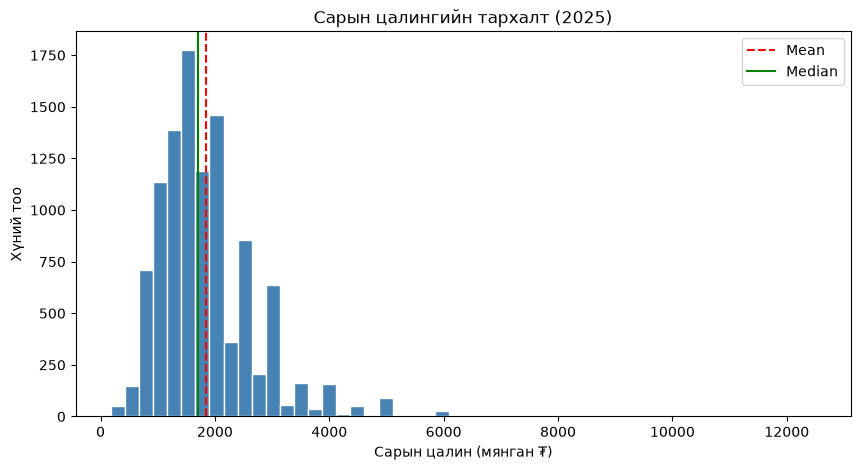

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(wage["f02"], bins=50, color="steelblue", edgecolor="white")

plt.axvline(wage["f02"].mean(), color="red", linestyle="--", label="Mean")
plt.axvline(wage["f02"].median(), color="green", linestyle="-", label="Median")

plt.title("Сарын цалингийн тархалт (2025)")
plt.xlabel("Сарын цалин (мянган ₮)")
plt.ylabel("Хүний тоо")
plt.legend()
plt.show()

Тайлбар
Код	Юу хийдэг вэ
figsize=(10, 5)	Зургийн өргөн ба өндөр (инчээр)
bins=50	Цалинг 50 багана-д хуваана. Багана бүр тодорхой цалингийн завсар
edgecolor="white"	Багануудын хооронд цагаан зураас татна. Ялгахад хялбар
plt.axvline(...)	Шинэ. Тухайн утга дээр босоо шугам татна. Mean ба median хаана байгааг харуулна
label= + plt.legend()	Шугам бүрийн нэрийг т

In [18]:
print("Эрэгтэй:", wage[wage["a03"] == 1]["f02"].median())
print("Эмэгтэй:", wage[wage["a03"] == 2]["f02"].median())

wage.groupby("a03")["f02"].agg(["count", "mean", "median", "std"])

Эрэгтэй: 2000.0
Эмэгтэй: 1500.0


,count,mean,median,std
a03,,,,
1,5377,2068.722485,2000.0,1049.152635
2,5176,1625.615920,1500.0,690.664180


.agg([...]) нь олон статистикийг нэг дор тооцоолно. describe()-ийн бүлэг тус бүрийн хувилбар гэж ойлгож болно.

In [19]:
edu_names = {
    1: "Боловсролгүй",
    2: "Бага",
    3: "Суурь",
    4: "Бүрэн дунд",
    5: "Техник/мэргэжлийн",
    6: "Тусгай мэргэжлийн дунд",
    7: "Дипломын дээд",
    8: "Бакалавр",
    9: "Магистр",
    10: "Доктор"
}

edu = wage.groupby("a28")["f02"].agg(["count", "median", "mean"])
edu = edu.rename(index=edu_names)
edu

,count,median,mean
a28,,,
Боловсролгүй,106,1100.0,1291.981132
Бага,110,1200.0,1398.190909
Суурь,434,1095.0,1283.746544
Бүрэн дунд,1138,1300.0,1485.364675
Техник/мэргэжлийн,3395,1600.0,1828.675052
Тусгай мэргэжлийн дунд,590,1500.0,1616.508475
Дипломын дээд,177,1600.0,1699.485876
Бакалавр,4014,1800.0,2022.845790
Магистр,574,2000.0,2394.709059


Тайлбар
Код	Юу хийдэг вэ
{ 1: "Боловсролгүй", ... }	Dictionary. түлхүүр: утга хосуудын жагсаалт. “1 гэдэг нь Боловсролгүй, 2 гэдэг нь Бага...” гэсэн орчуулгын хүснэгт гэж ойлго
edu_names = ...	Тэр толь бичгийг нэр өгч хадгална. Дараа нь дахин ашиглаж болно
.rename(index=edu_names)	Хүснэгтийн мөрийн нэрс (index)-ийг толь бичгээр солино: 1 → "Боловсролгүй" г.м.

In [20]:
bins = [15, 25, 35, 45, 55, 65, 100]
labels = ["15–24", "25–34", "35–44", "45–54", "55–64", "65+"]

wage["age_group"] = pd.cut(wage["a05"], bins=bins, labels=labels, right=False)

wage.groupby("age_group", observed=True)["f02"].agg(["count", "median", "mean"])

C:\Users\97680\AppData\Local\Temp\ipykernel_12640\61870627.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  wage["age_group"] = pd.cut(wage["a05"], bins=bins, labels=labels, right=False)


,count,median,mean
age_group,,,
15–24,948,1500.0,1687.067511
25–34,2876,1800.0,1940.628999
35–44,3442,1800.0,1969.766705
45–54,2396,1560.0,1766.158932
55–64,823,1400.0,1541.705954
65+,68,1000.0,1127.088235


Тайлбар
Код	Юу хийдэг вэ
bins	Бүлгийн хилүүд: 15, 25, 35...
labels	Бүлэг бүрийн нэр. Хилийн тооноос 1-ээр бага байх ёстой (7 хил → 6 бүлэг)
pd.cut(...)	Шинэ. Тоон утгыг завсраар бүлэглэнэ. Histogram-ийн bins-тэй адил санаа
right=False	Баруун хилийг оруулахгүй: 25 настай хүн “15–24”-т биш, “25–34”-т орно
observed=True	Хоосон бүлгийг харуулахгүй. Үүнийг бичихгүй бол анхааруулга гарч магадгүй

In [21]:
lf = df[df["a05"] >= 15]

print(lf.shape)
print("Ажиллагч:", lf["e04"].notna().sum())
print("Ажиллаагүй:", lf["e04"].isna().sum())

(34404, 203)
Ажиллагч: 19567
Ажиллаагүй: 14837


Код	Юу хийдэг вэ
df["a05"] >= 15	15 ба түүнээс дээш насны хүмүүст True
lf = df[...]	Тэднийг lf (labour force) гэсэн шинэ хүснэгтэд хадгална. Даалгавар 6-ийн шүүлттэй ижил арга
.notna().sum()	e04 бөглөгдсөн хүний тоо = ажиллагч
.isna().sum()	e04 хоосон хүний тоо = ажиллаагүй (ажилгүй + ажиллах хүчнээс гадуурх)

In [22]:
search = (lf["h01a"] == 1) | (lf["h01b"] == 1) | (lf["h02"] == 1)
avail = (lf["h10"] == 1) | (lf["h11"] == 1)

unemp = lf["e04"].isna() & search & avail

print("Ажилгүй:", unemp.sum())

Ажилгүй: 1299


In [23]:
emp = lf["e04"].notna().sum()
une = unemp.sum()
pop = len(lf)
labour = emp + une

print("Оролцоо:", labour / pop * 100)
print("Ажилгүйдэл:", une / labour * 100)
print("Хөдөлмөр эрхлэлт:", emp / pop * 100)

Оролцоо: 60.649924427392165
Ажилгүйдэл: 6.225438512412537
Хөдөлмөр эрхлэлт: 56.874200674340194


Код мөр бүрээр
Мөр	Юу хийж байна	Утга
emp = lf["e04"].notna().sum()	e04 бөглөгдсөн хүнийг тоолно	19,567 ажиллагч
une = unemp.sum()	Даалгавар 17-д үүсгэсэн True/False жагсаалтаас True-г тоолно	1,299 ажилгүй
pop = len(lf)	lf-ийн мөрийн тоо	34,404 (15+ насны бүх хүн)
labour = emp + une	Ажиллагч + ажилгүй	20,866 (ажиллах хүч)

In [24]:
lf = lf.copy()
lf["status"] = "Гадуур"
lf.loc[lf["e04"].notna(), "status"] = "Ажиллагч"
lf.loc[unemp, "status"] = "Ажилгүй"

pd.crosstab(lf["a03"], lf["status"])

status,Ажилгүй,Ажиллагч,Гадуур
a03,,,
1,755,10480,5172
2,544,9087,8366


Код	Юу хийдэг вэ
lf.copy()	lf-ийг бие даасан хуулбар болгоно. Шинэ багана нэмэхэд анхааруулга гарахгүй
lf["status"] = "Гадуур"	Шинэ багана үүсгээд эхлээд бүгдийг "Гадуур" гэж тэмдэглэнэ
lf.loc[нөхцөл, "status"] = "..."	Шинэ. Нөхцөл хангасан мөрүүдийн status-ыг солино. Эхлээд ажиллагчдыг, дараа нь ажилгүйчүүдийг тэмдэглэнэ
pd.crosstab(A, B)	Шинэ. A (хүйс) ба B (статус)-ийн хослол бүрээр хүнийг тоолсон хүснэгт

In [25]:
# Эрэгтэй
emp_m = (lf["e04"].notna() & (lf["a03"] == 1)).sum()
une_m = (unemp & (lf["a03"] == 1)).sum()
pop_m = (lf["a03"] == 1).sum()

# Эмэгтэй
emp_f = (lf["e04"].notna() & (lf["a03"] == 2)).sum()
une_f = (unemp & (lf["a03"] == 2)).sum()
pop_f = (lf["a03"] == 2).sum()

print("Эрэгтэй оролцоо:", (emp_m + une_m) / pop_m * 100)
print("Эмэгтэй оролцоо:", (emp_f + une_f) / pop_f * 100)

Эрэгтэй оролцоо: 68.47686962881697
Эмэгтэй оролцоо: 53.51447463466133


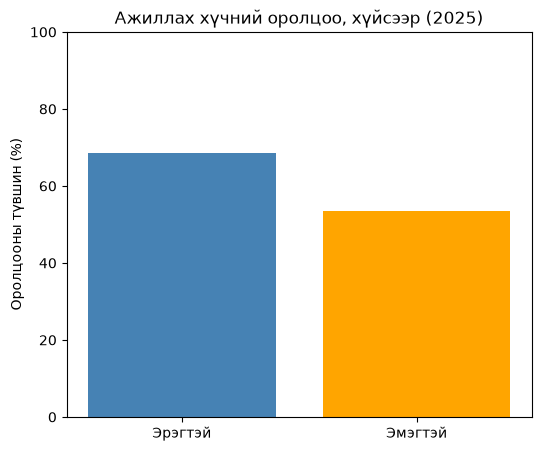

In [26]:
part_m = (emp_m + une_m) / pop_m * 100
part_f = (emp_f + une_f) / pop_f * 100

plt.figure(figsize=(6, 5))
plt.bar(["Эрэгтэй", "Эмэгтэй"], [part_m, part_f], color=["steelblue", "orange"])
plt.title("Ажиллах хүчний оролцоо, хүйсээр (2025)")
plt.ylabel("Оролцооны түвшин (%)")
plt.ylim(0, 100)
plt.savefig("bar_participation.png", dpi=150)
plt.show()

Код	Юу хийдэг вэ
plt.bar(нэрс, утгууд)	Нэр бүрт өндөр нь утгатай тэнцүү багана зурна
plt.ylim(0, 100)	Босоо тэнхлэгийг 0-100% болгоно. 0-ээс эхлүүлэх нь зөрүүг зөв харьцаагаар харуулна
plt.savefig(...)	Зургийг файл болгож хадгална. Тайлан, слайдад хэрэгтэй

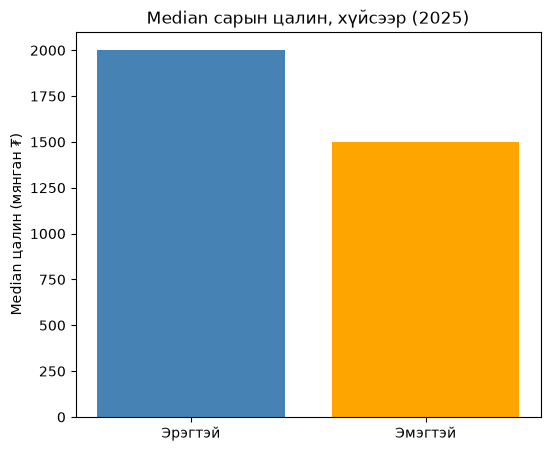

In [27]:
sex_med = wage.groupby("a03")["f02"].median()

plt.figure(figsize=(6, 5))
plt.bar(["Эрэгтэй", "Эмэгтэй"], sex_med, color=["steelblue", "orange"])
plt.title("Median сарын цалин, хүйсээр (2025)")
plt.ylabel("Median цалин (мянган ₮)")
plt.savefig("bar_wage_sex.png", dpi=150)
plt.show()

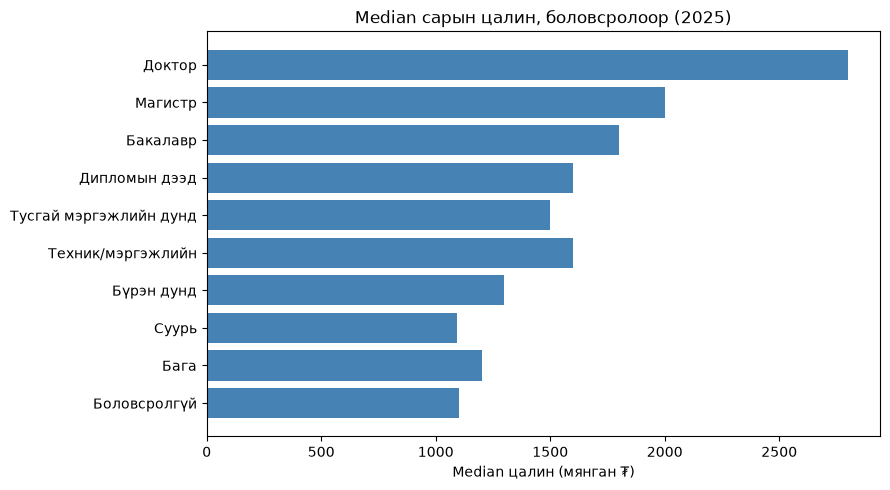

In [ ]:
plt.figure(figsize=(9, 8))
plt.barh(edu.index, edu["median"], color="steelblue")
plt.title("Median сарын цалин, боловсролоор (2025)")
plt.xlabel("Median цалин (мянган ₮)")
plt.tight_layout()
plt.savefig("bar_wage_edu.png", dpi=150)
plt.show()